# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [5]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

# Render charts as static PNGs so they display on GitHub (needs: pip install kaleido)
pio.renderers.default = 'png'


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [6]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 106.6 KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: <StringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


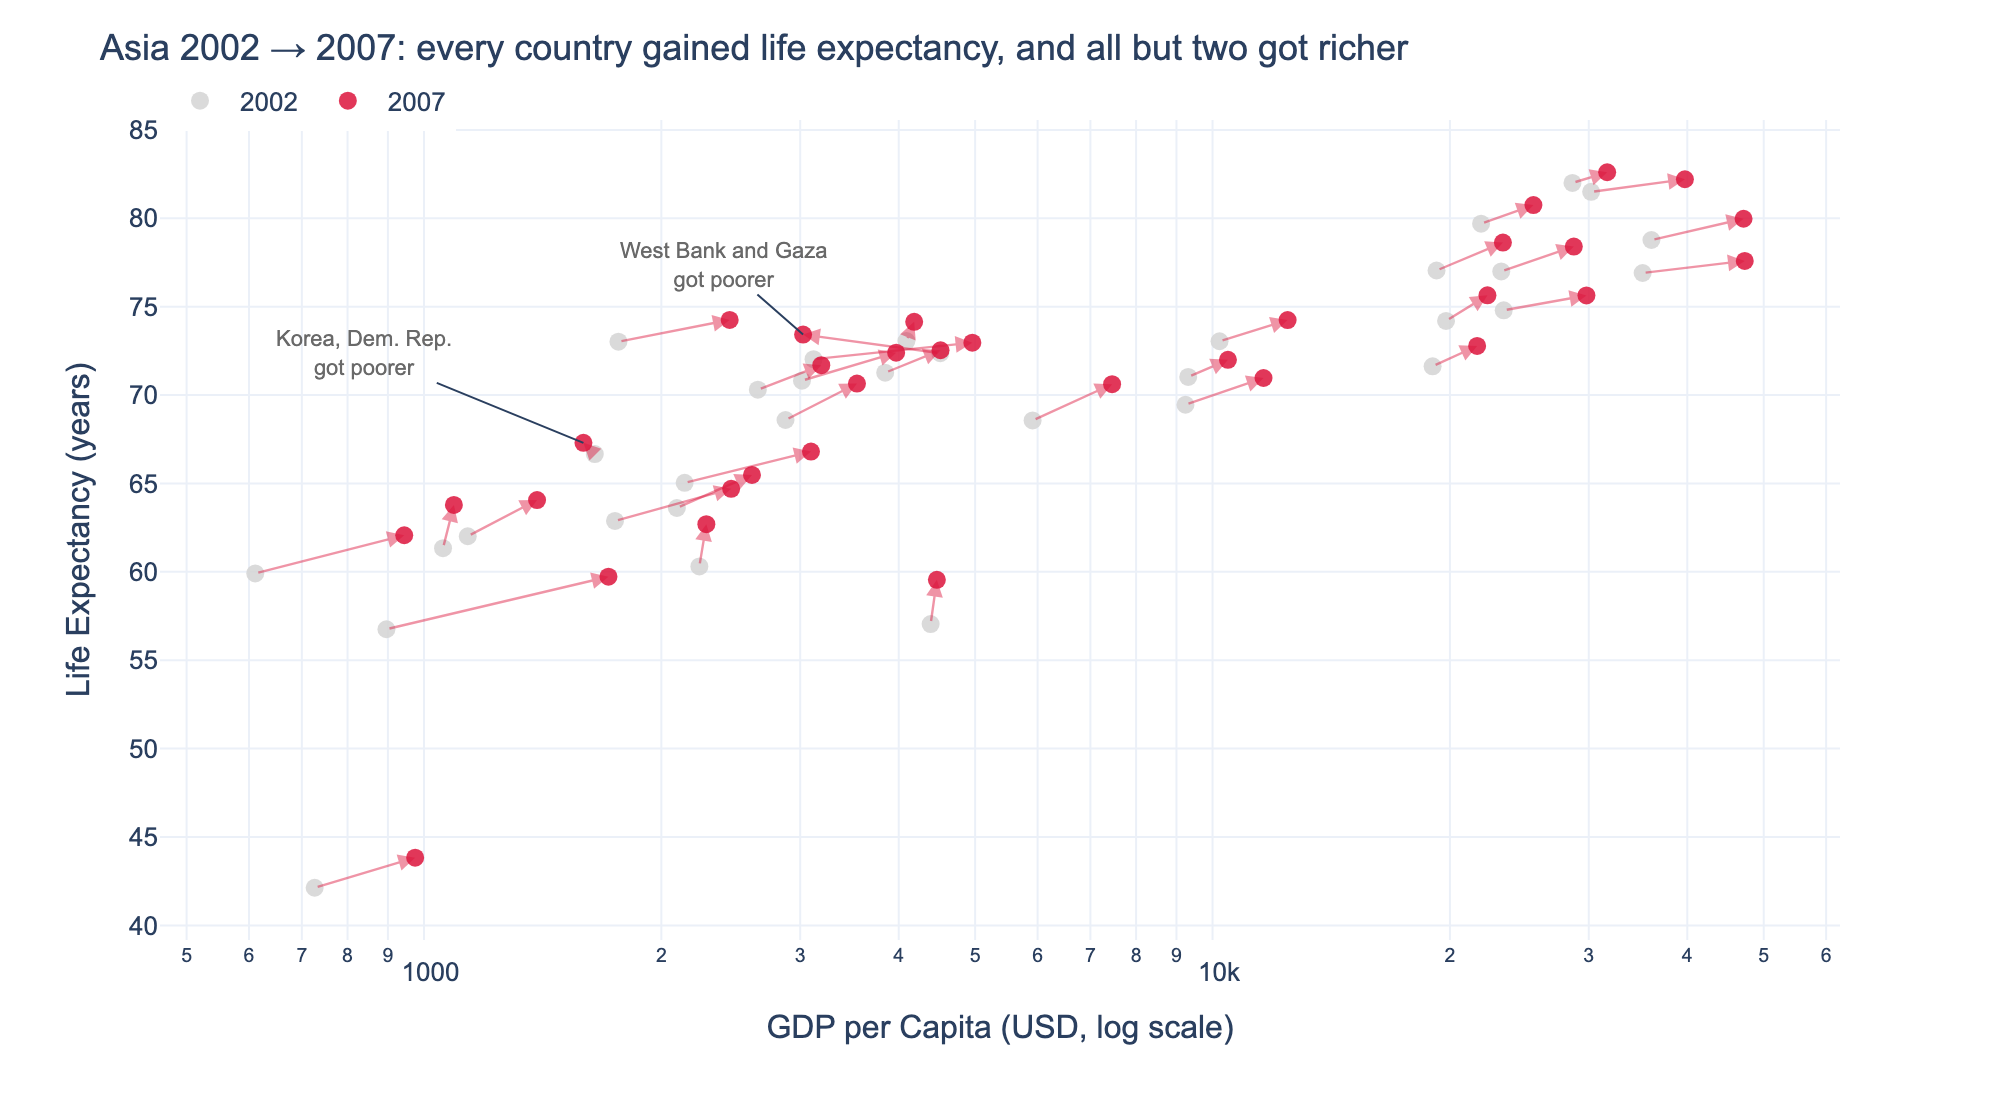

In [7]:
# Task 1
import math

continent = 'Asia'
years = [2002, 2007]
asia = df.loc[(df['continent'] == continent) & (df['year'].isin(years))].copy()
asia['year'] = asia['year'].astype(str)          # treat year as a category -> 2 discrete colours

colour_map = {'2002': 'lightgrey', '2007': 'crimson'}   # old = grey (context), new = colour (focus)

fig = px.scatter(
    data_frame=asia, x='gdpPercap', y='lifeExp',
    color='year',
    color_discrete_map=colour_map,
    category_orders={'year': ['2002', '2007']},
    hover_name='country',
    log_x=True,                                   # wealth is non-linear
    labels={'gdpPercap': 'GDP per Capita (USD, log scale)',
            'lifeExp': 'Life Expectancy (years)', 'year': ''},
    template='plotly_white',
)
fig.update_traces(marker=dict(size=9, opacity=0.85))

# Arrows from each country's 2002 position to its 2007 position -> shows the direction of change
wide = asia.pivot(index='country', columns='year', values=['gdpPercap', 'lifeExp'])
for country, r in wide.iterrows():
    fig.add_annotation(
        x=math.log10(r[('gdpPercap', '2007')]), y=r[('lifeExp', '2007')],
        ax=math.log10(r[('gdpPercap', '2002')]), ay=r[('lifeExp', '2002')],
        xref='x', yref='y', axref='x', ayref='y',
        showarrow=True, arrowhead=2, arrowsize=1.4, arrowwidth=1.2,
        arrowcolor='rgba(220, 20, 60, 0.45)', text=''
    )

# Call out the two countries that moved backwards on wealth
for country, dx, dy in [('West Bank and Gaza', -40, -35), ('Korea, Dem. Rep.', -110, -45)]:
    r = wide.loc[country]
    fig.add_annotation(
        x=math.log10(r[('gdpPercap', '2007')]), y=r[('lifeExp', '2007')],
        text=f'{country}<br>got poorer', showarrow=True, arrowhead=0,
        ax=dx, ay=dy, font=dict(size=11, color='dimgrey')
    )

fig.update_layout(
    title='Asia 2002 → 2007: every country gained life expectancy, and all but two got richer',
    font=dict(family='Arial', size=13),
    legend=dict(orientation='h', x=0, y=1.06, title=''),
    height=550, width=1000
)
fig.show(scale=2)   # PNG at 2x for sharpness


**Insight (Task 1):** All 33 Asian countries moved **up** (median +1.4 years of life expectancy) and 31 of 33 moved **right** (median GDP per capita +23%). The only countries that got poorer were West Bank and Gaza and North Korea. Arrows point from 2002 (grey) to 2007 (red).

## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


In [ ]:
# Task 2
import math

d07 = df.loc[df['year'] == 2007].copy()

highlight_continent = 'Asia'
colour_map = {c: ('crimson' if c == highlight_continent else 'lightgrey') for c in d07['continent'].unique()}

fig = px.scatter(
    data_frame=d07, x='gdpPercap', y='lifeExp',
    size='pop', size_max=60,                      # cap bubble size so small countries stay visible
    color='continent',
    color_discrete_map=colour_map,
    category_orders={'continent': [c for c in d07['continent'].unique() if c != highlight_continent] + [highlight_continent]},  # draw Asia on top
    hover_name='country',
    custom_data=['continent', 'pop'],
    log_x=True,
    labels={'gdpPercap': 'GDP per Capita (USD, log scale)',
            'lifeExp': 'Life Expectancy (years)', 'pop': 'Population'},
    template='plotly_white',
    opacity=0.75,
)
fig.update_traces(
    hovertemplate='<b>%{hovertext}</b> (%{customdata[0]})<br>'
                  'GDP per capita: $%{x:,.0f}<br>'
                  'Life expectancy: %{y:.1f} yrs<br>'
                  'Population: %{customdata[1]:,.0f}<extra></extra>'
)

# Annotations: the Asia story is its range — giants in the middle, extremes at both ends
for country, label, ax, ay in [
    ('China', 'China: 1.3 bn people,<br>$5k GDP, 73 yrs', -110, -55),
    ('India', 'India: 1.1 bn people,<br>$2.5k GDP, 65 yrs', -40, 70),
    ('Japan', 'Japan: 83 yrs,<br>highest in the world', -40, -45),
    ('Afghanistan', 'Afghanistan: 44 yrs', 60, 30),
]:
    r = d07.loc[d07['country'] == country].iloc[0]
    fig.add_annotation(
        x=math.log10(r['gdpPercap']), y=r['lifeExp'], text=label,
        showarrow=True, arrowhead=0, arrowcolor='crimson', ax=ax, ay=ay,
        font=dict(size=11, color='crimson', family='Arial'),
        bgcolor='rgba(255,255,255,0.85)'
    )

fig.add_annotation(
    x=math.log10(250), y=82, xanchor='left', align='left', showarrow=False,
    text='<b>Asia</b> spans almost the whole chart:<br>a 39-year life-expectancy gap between<br>Afghanistan and Japan in one continent',
    font=dict(color='crimson', size=12, family='Arial'),
    bgcolor='white', bordercolor='crimson', borderwidth=1, borderpad=6
)

fig.update_layout(
    title='Asia holds both extremes: the world\'s longest-lived nation and one of its shortest',
    font=dict(family='Arial', size=13),
    showlegend=False,
    xaxis=dict(range=[math.log10(200), math.log10(60000)]),
    height=600, width=1100
)
fig.show(scale=2)   # PNG at 2x for sharpness


**Insight (Task 2):** Asia (red) is the only continent that covers almost the full range of the chart. Its two population giants, China and India, sit in the middle on both wealth and health, while Japan (83 years) and Afghanistan (44 years) mark the two ends. All other continents are grey for context.